# Matching the prior and the level spacing of IHDM to brain MRI: a tutorial

Inverse heat dissipation models (IHDM; Rissanen, Heinonen and Solin, ICLR 2023,
[arXiv 2206.13397](https://arxiv.org/abs/2206.13397)) replace the Gaussian noise of a diffusion
model by the heat equation, which blurs an image instead of burying it in noise. A network
learns to undo one small blur step at a time, and sampling starts from a blurred training image.
Two settings of the model depend on the data: the terminal blur of the prior and the spacing of
the blur levels. The paper chose both for natural images. We set them from the statistics of
registered brain MRI and measure what the change gains and what it costs.

In this tutorial you will:

- write the heat forward operator $F(t)$ in a few lines of NumPy and check it against the
  released PyTorch code;
- measure where the between-image variance of brain slices and of photographs lies in
  frequency;
- compute how much of a training image the prior hands to the sampler, at the paper's terminal
  blur and at ours;
- compute how the paper's logarithmic level spacing and our matched spacing spread the
  regression target over the levels;
- read the results of our experiment, re-plotted from small files.

The notebook does not train or sample. Training needs a GPU, and sampling needs the trained
checkpoints, which are not in the repository, so every result in Section 7 is loaded from a
file. The notebook runs on a CPU and reads only files tracked in the repository; the last cell
prints its run time. The full discussion of the results is in
[`docs/RESULTS/results_discussion.md`][results-discussion]. Formulas follow the
course notation, as in the Methodology (Section 4) and Appendix C of our report.

[results-discussion]: https://github.com/MarioPasc/generative-inverse-heat-dissipation/blob/main/docs/RESULTS/results_discussion.md

## 1. Setup

We import the light modules of the `ihdm` package (NumPy and SciPy only) and the released
forward operator `DCTBlur` from `model_code`. Every path is relative to the repository root, and
the cell ends by checking that each file the notebook reads exists.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image as ShowImage
from PIL import Image
from scipy.fft import dctn, idctn

import ihdm
from ihdm.analysis.tutorial import plot_distance, plot_octave_errors, plot_precision_recall
from ihdm.paths import repo_root
from ihdm.spectral.power import (
    eigenvalues,
    fit_alpha,
    inherited_share,
    octave_bins,
    octave_shares,
    power_law,
    radial_index,
    radial_spectrum,
)
from ihdm.spectral.schedules import (
    ScheduleSpec,
    levels_per_octave,
    log_schedule,
    per_level_removed,
    per_level_spread,
)
from model_code.utils import DCTBlur

started = time.perf_counter()
plt.rcParams.update({"figure.dpi": 90, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False})

REPO = repo_root()
ASSETS = REPO / "assets"
PROFILES = REPO / "docs" / "RESULTS" / "data_profile"
SCHEDULES = REPO / "schedules"
SCHEDULE_NAMES = ("log_W2", "ixi_W2", "log_W8", "ixi_W8")
W = 192  # image side in pixels

needed = [
    ASSETS / "images" / "manifest.json",
    ASSETS / "results" / "f2_results.json",
    PROFILES / "ixi.npz",
    PROFILES / "lsun_church.npz",
    REPO / "docs" / "RESULTS" / "paper" / "f2_arms.png",
    *(SCHEDULES / f"{name}.npy" for name in SCHEDULE_NAMES),
]
missing = [path.relative_to(REPO) for path in needed if not path.is_file()]
assert not missing, f"missing files: {missing}"
# relative_to raises if ihdm is imported from another checkout than this one
print("ihdm imported from <repository>/" + str(Path(ihdm.__file__).resolve().relative_to(REPO)))
print(f"{len(needed)} input files found")

ihdm imported from <repository>/ihdm/__init__.py
9 input files found


## 2. Two kinds of images

We compare two image sets with very different statistics. The IXI slices are axial slices of
T1-weighted brain volumes, rigidly registered to the MNI152 template, bias-corrected and scaled
to $[0, 1]$; each is $192\times192$ pixels. The LSUN Churches images are photographs of
churches, converted to grayscale and centre-cropped to the same size. Images of the *train*
split were used to train the models. *Seed* images are held out: held-out subjects for IXI,
held-out photographs for Churches. `assets/README.md` gives the provenance and licence of each
file.

ixi_3705           (192, 192) IXI607        split=seed
ixi_3311           (192, 192) IXI541        split=train
lsun_church_1180   (192, 192) church_01180  split=train
lsun_church_107    (192, 192) church_00107  split=seed


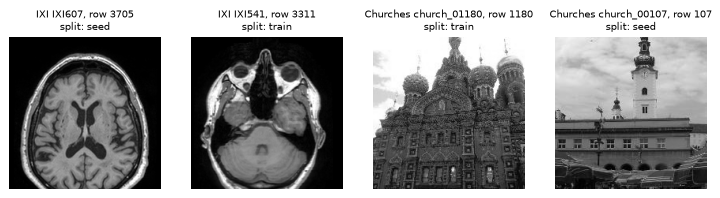

In [2]:
manifest = json.loads((ASSETS / "images" / "manifest.json").read_text())["images"]
images, labels = {}, {}
for entry in manifest:
    key = entry["file"].removesuffix(".png")
    images[key] = np.asarray(Image.open(ASSETS / "images" / entry["file"]), np.float64) / 255.0
    name = "IXI" if entry["dataset_id"] == "ixi" else "Churches"
    labels[key] = f"{name} {entry['subject']}, row {entry['row']}\nsplit: {entry['split']}"
    print(f"{key:18s} {images[key].shape} {entry['subject']:13s} split={entry['split']}")

fig, axes = plt.subplots(1, 4, figsize=(10, 2.9))
for ax, key in zip(axes, images, strict=True):
    ax.imshow(images[key], cmap="gray", vmin=0, vmax=1)
    ax.set_title(labels[key], fontsize=8)
    ax.axis("off")
plt.show()

The brain slices share their layout: after registration the head sits in the same place in
every image, and the slices differ in the anatomy inside it. The photographs do not share a
layout; each scene has its own composition. Sections 4 to 6 show what this does to the two
settings we change.

## 3. The forward process: heat instead of noise

Score-based diffusion with the variance-preserving SDE (DDPM in discrete time) has the marginal

$$q(\mathbf{x}_t\mid\mathbf{x}_0)=\mathcal{N}\big(\sqrt{\bar\alpha_t}\,\mathbf{x}_0,\,
(1-\bar\alpha_t)\mathbf{I}\big).$$

Its mean shrinks every direction of the image by the same factor $\sqrt{\bar\alpha_t}$, while the
noise grows until it hides the image. IHDM keeps the Gaussian form and changes the mean. It runs
the heat equation $\partial_t\mathbf{u}=\Delta\mathbf{u}$ on the image
$\mathbf{u}\in\mathbb{R}^{W\times W}$, with $\mathbf{u}(0)=\mathbf{x}$. With Neumann boundaries
the Laplacian is diagonal in the orthonormal 2-D discrete cosine transform (DCT) basis
$\mathbf{V}$, so that

$$\mathbf{u}(t)=F(t)\,\mathbf{x},\qquad F(t)=\mathbf{V}e^{-\boldsymbol\Lambda t}\mathbf{V}^\top,
\qquad \lambda_i=\pi^2(n_i^2+m_i^2)/W^2 ,$$

where mode $i=(n_i,m_i)$ is the DCT basis image with $n_i$ and $m_i$ half periods along the two
axes. $F(t)$ shrinks each mode by its own factor $e^{-\lambda_i t}$, and time $t$ acts as a
Gaussian blur of width $\sigma_B=\sqrt{2t}$ pixels. IHDM blurs to $K$ levels
$t_k=\sigma_{B,k}^2/2$ and adds noise of a small, fixed standard deviation $\sigma$:

$$q(\mathbf{u}_k\mid\mathbf{u}_0)=\mathcal{N}\big(F(t_k)\,\mathbf{u}_0,\,
\sigma^2\mathbf{I}\big).$$

The scalar $\sqrt{\bar\alpha_t}$ of DDPM has become the operator $F(t_k)$, and the variance no
longer grows with $k$ (report, Section 4.1; derivation in Appendix C).

$F(t)$ takes one line of NumPy: transform to the DCT basis, scale each coefficient, transform
back. `scipy.fft.dctn(..., norm="ortho")` applies $\mathbf{V}^\top$ and `idctn` applies
$\mathbf{V}$.

In [3]:
lam = eigenvalues(W)  # (W, W): lambda_i = pi^2 (n_i^2 + m_i^2) / W^2


def heat(u, sigma_b):
    """F(t) u for an image u of shape (W, W), with t = sigma_B^2 / 2."""
    t = sigma_b**2 / 2
    return idctn(np.exp(-lam * t) * dctn(u, norm="ortho"), norm="ortho")

The released code applies the same operator in PyTorch: `model_code.utils.DCTBlur` takes a table
of blur widths and blurs a batch to the requested entries. We build it with five widths and
compare it with `heat` on one IXI slice.

In [4]:
sigmas_b = [0.0, 2.0, 8.0, 24.0, 96.0]
released = DCTBlur(sigmas_b, W, "cpu")
slice_ixi = images["ixi_3705"]
x = torch.from_numpy(slice_ixi).float()[None, None]  # (1, 1, W, W) float32, as in training
for k, s in enumerate(sigmas_b):
    ours = heat(slice_ixi, s)
    theirs = released(x, torch.tensor([k]))[0, 0].double().numpy()
    print(f"sigma_B = {s:4.0f} px: max |heat - DCTBlur| = {np.abs(ours - theirs).max():.1e}")

sigma_B =    0 px: max |heat - DCTBlur| = 3.3e-07
sigma_B =    2 px: max |heat - DCTBlur| = 2.5e-07
sigma_B =    8 px: max |heat - DCTBlur| = 1.9e-07
sigma_B =   24 px: max |heat - DCTBlur| = 1.7e-07
sigma_B =   96 px: max |heat - DCTBlur| = 1.1e-07


The largest difference is of the order of float32 rounding: our function `heat` and the released
operator compute the same $F(t)$. The next figure blurs one brain slice and one photograph to
$\sigma_B\in\{0, 2, 8, 24, 96\}$ px.

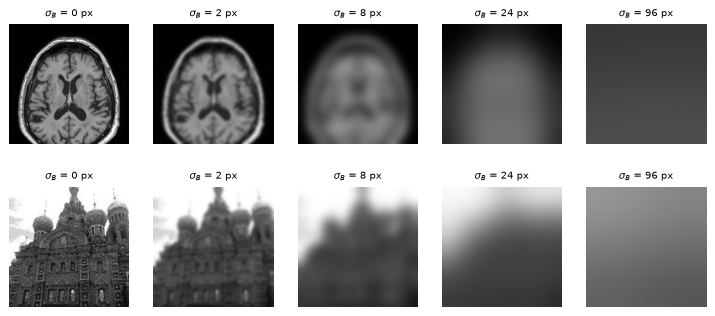

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.3))
for row, key in zip(axes, ("ixi_3705", "lsun_church_1180"), strict=True):
    for ax, s in zip(row, sigmas_b, strict=True):
        ax.imshow(heat(images[key], s), cmap="gray", vmin=0, vmax=1)
        ax.set_title(rf"$\sigma_B$ = {s:g} px", fontsize=8)
        ax.axis("off")
plt.show()

Fine detail disappears first. In image units, $\lambda_i t=(c_i\sigma_B/\omega)^2$, where
$c_i=\frac12\sqrt{n_i^2+m_i^2}$ is the frequency of mode $i$ in cycles per image (c/img) and
$\omega=W/(\sqrt2\pi)$. Mode $i$ keeps $e^{-1}$ of its amplitude at $\sigma_B=\omega/c_i$, so a
blur of width $\sigma_B$ leaves the modes below $\omega/\sigma_B$ c/img largely intact and
removes most of those above it.

In [6]:
omega = W / (np.sqrt(2) * np.pi)
print(f"omega = W / (sqrt(2) pi) = {omega:.1f} px")
for s in sigmas_b[1:]:
    print(f"sigma_B = {s:4.0f} px: modes below omega / sigma_B = {omega / s:5.2f} c/img keep "
          "more than 1/e of their amplitude")

omega = W / (sqrt(2) pi) = 43.2 px
sigma_B =    2 px: modes below omega / sigma_B = 21.61 c/img keep more than 1/e of their amplitude
sigma_B =    8 px: modes below omega / sigma_B =  5.40 c/img keep more than 1/e of their amplitude
sigma_B =   24 px: modes below omega / sigma_B =  1.80 c/img keep more than 1/e of their amplitude
sigma_B =   96 px: modes below omega / sigma_B =  0.45 c/img keep more than 1/e of their amplitude


At 96 px only modes below 0.45 c/img keep that much, and on the $192^2$ grid the only such mode
is the DC (the mean intensity), so the image is nearly flat. At 24 px the modes below 1.80 c/img
survive.

## 4. Where the between-image variance lives

Both changes are set from one statistic of the training images: the between-image variance of
each DCT mode. With $M$ training images $\mathbf{x}^{(j)}$ and their mean image
$\bar{\mathbf{x}}$,

$$P_i=\frac{1}{M}\sum_{j=1}^{M}\Big[\mathbf{V}^\top\big(\mathbf{x}^{(j)}-\bar{\mathbf{x}}\big)
\Big]_i^2 ,$$

with the DC mode excluded (report, Section 4.2). `ihdm.spectral.power.mode_power` computes it
from an image stack. It needs the $M=3{,}200$ training images of each dataset, which are not in
the repository, so we load its stored output `power_train` from
`docs/RESULTS/data_profile/<dataset>.npz` (written by `python -m ihdm.cli.profile_data`). As a
third spectrum we build $P(c)\propto c^{-2}$ on the same $192^2$ grid with
`ihdm.spectral.power.power_law`: the law that natural images follow roughly.

In [7]:
profile = {name: np.load(PROFILES / f"{name}.npz") for name in ("ixi", "lsun_church")}
P = {
    "IXI": profile["ixi"]["power_train"],
    "Churches": profile["lsun_church"]["power_train"],
    "synthetic c^-2": power_law(W, 2.0, 1.0),
}
COLORS = {"IXI": "#EE6677", "Churches": "#4477AA", "synthetic c^-2": "0.4"}
for name, p in P.items():
    print(f"{name:15s} shape {p.shape} {p.dtype}, P_DC = {p[0, 0]:.0f}, sum_i P_i = {p.sum():.1f},"
          f" fitted exponent (10-67 c/img) = {fit_alpha(p):.2f}")

IXI             shape (192, 192) float64, P_DC = 0, sum_i P_i = 1259.3, fitted exponent (10-67 c/img) = 3.22
Churches        shape (192, 192) float64, P_DC = 0, sum_i P_i = 1873.3, fitted exponent (10-67 c/img) = 2.28
synthetic c^-2  shape (192, 192) float64, P_DC = 0, sum_i P_i = 1.0, fitted exponent (10-67 c/img) = 2.00


Panel (a) averages $P_i$ over rings of equal frequency and divides each spectrum by its total
variance; the synthetic spectrum is a straight line of slope $-2$. Panel (b) sums $P_i$ over
eight octaves of frequency, from 0.5–1 to 64–96 c/img, and divides by the total over the eight.
The modes above 96 c/img (the corners of the DCT grid) belong to no octave. The next cell first
counts the modes in each octave.

In [8]:
cycles = radial_index(W) / 2  # c_i of every mode, (W, W)
bins = octave_bins()
# half-open bins, the last one closed at 96 c/img, as in octave_shares
counts = [int(((cycles >= lo) & ((cycles < hi) | ((hi == 96.0) & (cycles == 96.0)))).sum())
          for _, lo, hi in bins]
print("modes per octave:", dict(zip([b[0] for b in bins], counts, strict=True)))
print("corner modes above 96 c/img:", int((cycles > 96.0).sum()))
shares = {name: octave_shares(p) for name, p in P.items()}
print(f"\n{'octave (c/img)':15s}" + "".join(f"{label:>8s}" for label, _, _ in bins))
for name, s in shares.items():
    print(f"{name:15s}" + "".join(f"{100 * v:7.1f}%" for v in s.values()))
# continuum c^-2: equal variance per full octave, so a bin's share is its width in octaves
continuum = [np.log2(hi / lo) / np.log2(96.0 / 0.5) for _, lo, hi in bins]
print(f"{'continuum c^-2':15s}" + "".join(f"{100 * v:7.1f}%" for v in continuum))
for name, key in (("IXI", "ixi"), ("Churches", "lsun_church")):
    stored = profile[key]["octave_shares_train"]
    print(f"{name} equals the stored octave_shares_train:",
          np.allclose(list(shares[name].values()), stored, rtol=0, atol=1e-12))

modes per octave: {'0.5-1': 3, '1-2': 11, '2-4': 41, '4-8': 158, '8-16': 619, '16-32': 2443, '32-64': 9709, '64-96': 16151}
corner modes above 96 c/img: 7728

octave (c/img)    0.5-1     1-2     2-4     4-8    8-16   16-32   32-64   64-96
IXI                4.1%   11.3%   11.0%   16.8%   29.8%   18.3%    7.8%    1.0%
Churches          23.8%   21.3%   16.1%   12.2%    9.6%    7.5%    6.1%    3.4%
synthetic c^-2    23.7%   15.2%   12.2%   11.2%   10.7%   10.5%   10.4%    6.1%
continuum c^-2    13.2%   13.2%   13.2%   13.2%   13.2%   13.2%   13.2%    7.7%
IXI equals the stored octave_shares_train: True
Churches equals the stored octave_shares_train: True


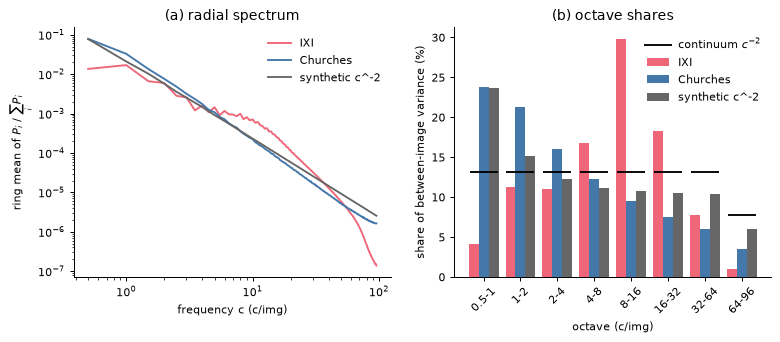

In [9]:
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(10, 3.6))
for name, p in P.items():
    c, mean_p = radial_spectrum(p)
    ax_a.loglog(c, mean_p / p.sum(), color=COLORS[name], label=name)
ax_a.set(xlabel="frequency c (c/img)", ylabel=r"ring mean of $P_i$ / $\sum_i P_i$",
         title="(a) radial spectrum")
ax_a.legend(frameon=False)
x_oct = np.arange(len(bins))
for j, (name, s) in enumerate(shares.items()):
    ax_b.bar(x_oct + (j - 1) * 0.27, [100 * v for v in s.values()], width=0.27,
             color=COLORS[name], label=name)
ax_b.plot(x_oct, [100 * v for v in continuum], "k_", markersize=22, markeredgewidth=1.5,
          label="continuum $c^{-2}$")
ax_b.set_xticks(x_oct, [b[0] for b in bins], rotation=45)
ax_b.set(xlabel="octave (c/img)", ylabel="share of between-image variance (%)",
         title="(b) octave shares")
ax_b.legend(frameon=False)
plt.show()

The shares are those of `docs/RESULTS/data_profile.md`, Section 2, and equal the stored arrays.
The photographs hold most of their variance at coarse frequencies: Churches puts 23.8% into the
three modes of 0.5–1 c/img. The brain slices hold little there (4.1% on IXI) and peak at 29.8%
in 8–16 c/img. Panel (a) shows the same difference: the fitted exponent is 2.28 for
Churches, close to the synthetic spectrum, and 3.22 for IXI, whose spectrum is curved.

On a continuous plane, a $c^{-2}$ spectrum holds the same variance in every full octave
(report, Appendix C). On these bins a bin's continuum share is
$\log_2(\text{hi}/\text{lo})/\log_2(96/0.5)$: 13.2% for each of the seven full octaves and
7.7% for the 0.58 octave 64–96 c/img (row `continuum c^-2` above; black marks in panel b). On
the $192^2$ grid the synthetic spectrum departs from it. It gives 23.7% to 0.5–1 c/img, 15.2% to
1–2 c/img and 6.1% to 64–96 c/img, and between 10.4% and 11.2% to each of the four octaves from
4 to 64 c/img. The coarsest octave holds three modes, too few for the continuum count, and
64–96 c/img is 0.58 of an octave. Equal shares per full octave therefore hold only roughly, and
only from about 4 c/img up.

## 5. Change 1: the prior

IHDM samples by running a learned reverse chain from $\mathbf{u}_K$ down to $\mathbf{u}_0$. The DC
mode never decays ($\lambda=0$), so the distribution of $\mathbf{u}_K$ depends on the data. IHDM
replaces it by its empirical version over the $M$ training images,

$$\hat p_K(\mathbf{u}_K)=\frac{1}{M}\sum_{j=1}^{M}\mathcal{N}\big(\mathbf{u}_K\mid
F(t_K)\,\mathbf{x}^{(j)},\;\delta^2\mathbf{I}\big).$$

A sample therefore starts from one training image, its *seed*, blurred to $t_K$, plus noise of
standard deviation $\delta$ (report, Section 4.1). The terminal blur $\sigma_{B,K}$ decides how
much of the seed survives. Rissanen et al. set $\sigma_{B,K}=W/2=96$ px; we set
$W/8=24$ px (report, Section 4.2). The figure shows the noise-free prior state
$F(t_K)\mathbf{x}^{(j)}$ of two training images at both values.

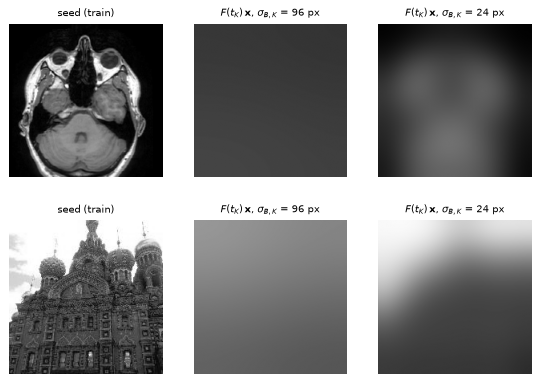

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(7.5, 5.2))
for row, key in zip(axes, ("ixi_3311", "lsun_church_1180"), strict=True):
    panels = [(images[key], "seed (train)")]
    panels += [(heat(images[key], s), rf"$F(t_K)\,\mathbf{{x}}$, $\sigma_{{B,K}}$ = {s:g} px")
               for s in (96.0, 24.0)]
    for ax, (img, title) in zip(row, panels, strict=True):
        ax.imshow(img, cmap="gray", vmin=0, vmax=1)
        ax.set_title(title, fontsize=8)
        ax.axis("off")
plt.show()

At 96 px both prior states are almost uniform, so the chain must generate the whole image. At
24 px the brain keeps a blurred outline of the head, and the church keeps the bright sky above
the dark building.

Mode $i$ of the seed reaches $\mathbf{u}_K$ scaled by $d_{K,i}=e^{-\lambda_i t_K}$. An ideal
sampler keeps this surviving part, the same in all samples of one seed, and regenerates the
removed part with its correct variance $(1-d_{K,i}^2)P_i$. It therefore inherits from the seed,
instead of generating, the share

$$I(\sigma_{B,K})=\frac{\sum_i d_{K,i}^2\,P_i}{\sum_i P_i}$$

of the between-image variance (report, Section 4.2). `ihdm.spectral.power.inherited_share`
evaluates it on the training-split spectra; the next cell draws it against $\sigma_{B,K}$.

IXI       I(24 px) =  8.5%   I(48 px) =  2.7%   I(96 px) =  0.3%   stored inherited_train [W/8, W/4, W/2] = [8.5 2.7 0.3]
Churches  I(24 px) = 29.1%   I(48 px) = 13.2%   I(96 px) =  1.8%   stored inherited_train [W/8, W/4, W/2] = [29.1 13.2  1.8]


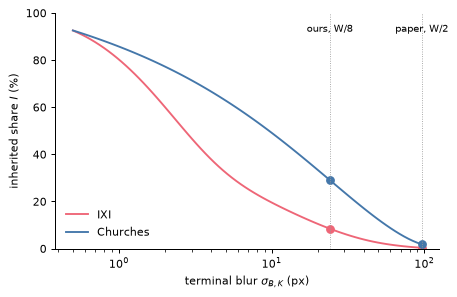

In [11]:
grid = np.geomspace(0.5, 96.0, 80)
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for name, key in (("IXI", "ixi"), ("Churches", "lsun_church")):
    curve = [100 * inherited_share(P[name], s) for s in grid]
    ax.semilogx(grid, curve, color=COLORS[name], label=name)
    marks = {s: 100 * inherited_share(P[name], s) for s in (24.0, 48.0, 96.0)}
    ax.plot([24.0, 96.0], [marks[24.0], marks[96.0]], "o", color=COLORS[name])
    print(f"{name:9s} I(24 px) = {marks[24.0]:4.1f}%   I(48 px) = {marks[48.0]:4.1f}%   "
          f"I(96 px) = {marks[96.0]:4.1f}%   stored inherited_train [W/8, W/4, W/2] = "
          f"{np.round(100 * profile[key]['inherited_train'], 1)}")
for s, text in ((24.0, "ours, W/8"), (96.0, "paper, W/2")):
    ax.axvline(s, color="0.6", linewidth=0.7, linestyle=":")
    ax.text(s, 92, text, ha="center", fontsize=8)
ax.set(xlabel=r"terminal blur $\sigma_{B,K}$ (px)", ylabel=r"inherited share $I$ (%)",
       ylim=(0, 100))
ax.legend(frameon=False)
plt.show()

On the training split, IXI inherits 8.5% of its between-image variance at 24 px and 0.3% at
96 px; Churches inherits 29.1% and 1.8%. These are the values of `docs/RESULTS/data_profile.md`,
Section 3, and of the stored `inherited_train`. At the same terminal blur a photograph hands
more than three times as much of itself to its samples as a brain slice does, because the
photographs keep their variance at the coarse frequencies that survive the blur. At 96 px the
brain prior keeps almost nothing, and the chain must also generate the head outline and the
coarse anatomy that all subjects share. $I$ is a prediction for an ideal sampler, not a
measurement. Its expected cost, samples that copy their seed, is measured in Section 7.

## 6. Change 2: the level spacing

The network $f_\theta$ predicts the step from $\mathbf{u}_k$ to the less blurred image. The loss
draws the level uniformly and gives every level the same weight:

$$\mathcal{L}(\theta)=\mathbb{E}_{k\sim\mathcal{U}\{1,\dots,K\}}\,
\mathbb{E}_{\mathbf{u}_0,\boldsymbol\epsilon}\big\|\mathbf{u}_k+f_\theta(\mathbf{u}_k,k)
-F(t_{k-1})\,\mathbf{u}_0\big\|_2^2,\qquad \mathbf{u}_k=F(t_k)\,\mathbf{u}_0+\sigma
\boldsymbol\epsilon .$$

Write $d_{k,i}=e^{-\lambda_i t_k}$ and $d_{0,i}=1$. Over images and noise, the regression target
$F(t_{k-1})\mathbf{u}_0-\mathbf{u}_k$ has total variance $E_k+W^2\sigma^2$, with

$$E_k=\sum_i\big(d_{k-1,i}-d_{k,i}\big)^2P_i$$

(report, Section 4.2; derivation in Appendix C). $E_k$ excludes the DC mode, as $P_i$ does,
while the noise term $W^2\sigma^2$ counts every pixel, DC included. The noise part is the same
at every level.
$E_k$ is the between-image variance of the level-$k$ target, the part of the image that level $k$
teaches the network to restore. Where the levels $t_k$ sit therefore decides how this variance,
and with it the training effort, is spread over the levels.
`ihdm.spectral.schedules.per_level_removed` returns $E_k$ for $k=2,\dots,K$, and
`per_level_spread` returns the spread $\max_k E_k/\min_k E_k$. $E_1$ is left out: it contains
the step from the unblurred image to $\sigma_{B,1}$, which no spacing controls.

Rissanen et al. space the levels logarithmically, $\sigma_{B,k}=\sigma_{B,1}r^{k-1}$, which puts
the same number of levels into every octave of $\sigma_B$. Our matched spacing places
$t_2,\dots,t_{K-1}$ so that $E_2=\dots=E_K$ on the IXI training split, with both endpoints
fixed. Algorithm 1 of the report (Section 4.2) finds it with two nested bisections, and
`ihdm.spectral.schedules.matched_schedule` implements it. One fit takes more than three
minutes on a CPU, so we load the four frozen schedules from `schedules/`, written by
`python -m ihdm.cli.build_schedules`. The names give the spacing (`log` or `ixi`-matched) and
the terminal blur (`W2`: 96 px, `W8`: 24 px). The log schedules can be rebuilt instantly, and
the cell checks that the rebuild equals the frozen file.

In [12]:
schedules = {name: np.load(SCHEDULES / f"{name}.npy") for name in SCHEDULE_NAMES}
for name, s in schedules.items():
    print(f"{name}: shape {s.shape}, sigma_B,0 = {s[0]:g}, sigma_B,1 = {s[1]:g} px, "
          f"sigma_B,K = {s[-1]:g} px")
for name, smax in (("log_W2", 96.0), ("log_W8", 24.0)):
    rebuilt = log_schedule(ScheduleSpec(kind="log", sigma_max=smax))
    print(f"log_schedule(sigma_max={smax:g}) equals {name}.npy:",
          np.array_equal(rebuilt, schedules[name]))

log_W2: shape (201,), sigma_B,0 = 0, sigma_B,1 = 0.5 px, sigma_B,K = 96 px
ixi_W2: shape (201,), sigma_B,0 = 0, sigma_B,1 = 0.5 px, sigma_B,K = 96 px
log_W8: shape (201,), sigma_B,0 = 0, sigma_B,1 = 0.5 px, sigma_B,K = 24 px
ixi_W8: shape (201,), sigma_B,0 = 0, sigma_B,1 = 0.5 px, sigma_B,K = 24 px
log_schedule(sigma_max=96) equals log_W2.npy: True
log_schedule(sigma_max=24) equals log_W8.npy: True


Panel (a) draws $\sigma_{B,k}$ against $k$ on a log axis, and panel (b) counts the levels in
each octave of $\sigma_B$, from 0.5–1 px to 64–96 px (`levels_per_octave`).

levels per octave (px)    0.5-1    1-2    2-4    4-8   8-16  16-32  32-64  64-96    sum
log_W2                       27     26     26     26     27     26     26     16    200
ixi_W2                       19     30     38     35     26     23     20      9    200
log_W8                       36     36     35     36     36     21      0      0    200
ixi_W8                       24     37     46     43     32     18      0      0    200
ixi_W2 moves 25 of 200 levels between octaves relative to log_W2
ixi_W8 moves 19 of 200 levels between octaves relative to log_W8


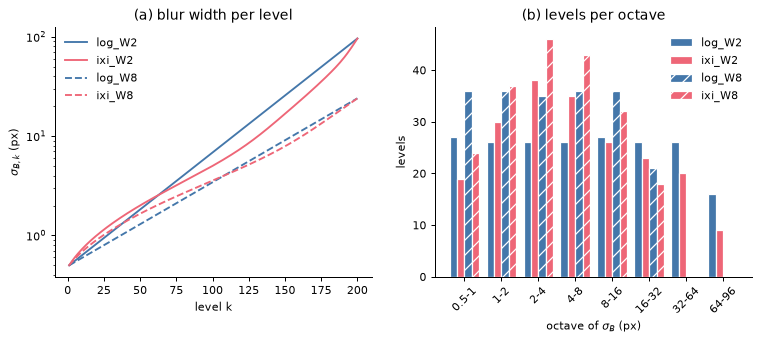

In [13]:
STYLES = {"log_W2": ("#4477AA", "-"), "ixi_W2": ("#EE6677", "-"),
          "log_W8": ("#4477AA", "--"), "ixi_W8": ("#EE6677", "--")}
per_octave = {name: levels_per_octave(s) for name, s in schedules.items()}
octaves_px = list(per_octave["log_W2"])
print(f"{'levels per octave (px)':24s}" + "".join(f"{o:>7s}" for o in octaves_px) + "    sum")
for name, counts_k in per_octave.items():
    print(f"{name:24s}" + "".join(f"{n:7d}" for n in counts_k.values())
          + f"{sum(counts_k.values()):7d}")
for log_name, ixi_name in (("log_W2", "ixi_W2"), ("log_W8", "ixi_W8")):
    moved = sum(max(per_octave[ixi_name][o] - per_octave[log_name][o], 0) for o in octaves_px)
    print(f"{ixi_name} moves {moved} of 200 levels between octaves relative to {log_name}")

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(10, 3.6))
for name, s in schedules.items():
    color, style = STYLES[name]
    ax_a.semilogy(np.arange(1, s.size), s[1:], style, color=color, label=name)
ax_a.set(xlabel="level k", ylabel=r"$\sigma_{B,k}$ (px)", title=r"(a) blur width per level")
ax_a.legend(frameon=False)
for j, (name, counts_k) in enumerate(per_octave.items()):
    color, style = STYLES[name]
    ax_b.bar(np.arange(8) + (j - 1.5) * 0.2, list(counts_k.values()), width=0.2, color=color,
             hatch="//" if style == "--" else None, edgecolor="white", label=name)
ax_b.set_xticks(np.arange(8), octaves_px, rotation=45)
ax_b.set(xlabel=r"octave of $\sigma_B$ (px)", ylabel="levels", title="(b) levels per octave")
ax_b.legend(frameon=False)
plt.show()

The log schedules are straight lines on the log axis and put 26 or 27 levels into every full
octave at 96 px, and 35 or 36 at 24 px, where the chain spans fewer octaves. The matched
schedules take more levels at 1–8 px and fewer below 1 px and above 8 px. The counts are those of
`docs/RESULTS/data_profile.md`, Section 5.

Panel (c) draws $E_k$ on the IXI spectrum for the four schedules. Panel (d) keeps the paper's
spacing at 96 px and changes the spectrum: IXI, Churches and the synthetic $c^{-2}$. Each curve
in (d) is divided by its mean over $k$, because the three spectra have different totals.

IXI, log_W2: spread max E_k / min E_k = 8.9x (8.8764); largest E_k at k = 74 (sigma_B = 3.4 px)
IXI, ixi_W2: spread max E_k / min E_k = 1.0x (1.0019); largest E_k at k = 200 (sigma_B = 96.0 px)
IXI, log_W8: spread max E_k / min E_k = 8.5x (8.5182); largest E_k at k = 100 (sigma_B = 3.4 px)


IXI, ixi_W8: spread max E_k / min E_k = 1.0x (1.0042); largest E_k at k = 200 (sigma_B = 24.0 px)


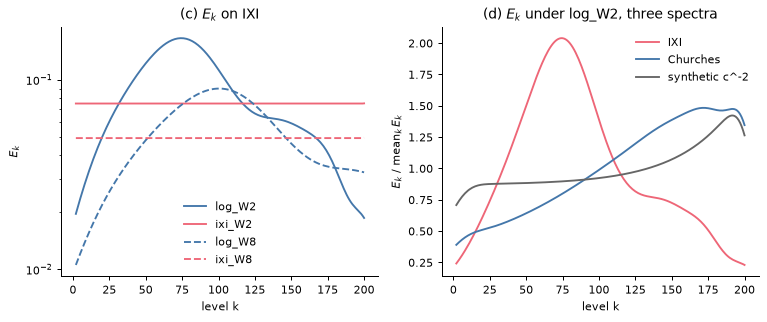

IXI             log_W2 spread = 8.9x   log_W8 spread = 8.5x
Churches        log_W2 spread = 3.8x   log_W8 spread = 3.5x
synthetic c^-2  log_W2 spread = 2.0x   log_W8 spread = 1.5x
synthetic c^-2, E_k / mean: k = 2: 0.71; k = 25: 0.88; k = 25-100: 0.88-0.92; max 1.42 at k = 192; k = 200: 1.26


In [14]:
k = np.arange(2, 201)  # per_level_removed returns E_2 ... E_K
fig, (ax_c, ax_d) = plt.subplots(1, 2, figsize=(10, 3.6))
for name, s in schedules.items():
    color, style = STYLES[name]
    ax_c.semilogy(k, per_level_removed(P["IXI"], s), style, color=color, label=name)
    e_k = per_level_removed(P["IXI"], s)
    print(f"IXI, {name}: spread max E_k / min E_k = {per_level_spread(P['IXI'], s):.1f}x "
          f"({per_level_spread(P['IXI'], s):.4f}); largest E_k at k = {k[e_k.argmax()]} "
          f"(sigma_B = {s[k[e_k.argmax()]]:.1f} px)")
ax_c.set(xlabel="level k", ylabel=r"$E_k$", title=r"(c) $E_k$ on IXI")
ax_c.legend(frameon=False)
for name, p in P.items():
    e_k = per_level_removed(p, schedules["log_W2"])
    ax_d.plot(k, e_k / e_k.mean(), color=COLORS[name], label=name)
ax_d.set(xlabel="level k", ylabel=r"$E_k$ / mean$_k\,E_k$",
         title=r"(d) $E_k$ under log_W2, three spectra")
ax_d.legend(frameon=False)
plt.show()
for name, p in P.items():
    print(f"{name:15s} log_W2 spread = {per_level_spread(p, schedules['log_W2']):.1f}x   "
          f"log_W8 spread = {per_level_spread(p, schedules['log_W8']):.1f}x")
ratio = per_level_removed(P["synthetic c^-2"], schedules["log_W2"])
ratio = ratio / ratio.mean()  # synthetic c^-2 under log_W2, E_k / mean_k E_k
middle = ratio[(k >= 25) & (k <= 100)]
print(f"synthetic c^-2, E_k / mean: k = 2: {ratio[0]:.2f}; k = 25: {ratio[k == 25][0]:.2f}; "
      f"k = 25-100: {middle.min():.2f}-{middle.max():.2f}; max {ratio.max():.2f} at "
      f"k = {k[ratio.argmax()]}; k = 200: {ratio[-1]:.2f}")

On IXI the paper's spacing makes $E_k$ vary by a factor of 8.9 at 96 px and 8.5 at 24 px. Under
`log_W2` the target variance peaks at level 74 ($\sigma_B$ = 3.4 px), and the first and last
levels carry little of it. The matched spacings bring the spread to 1.0 at both terminal blurs,
as their fit requires.

Panel (d) explains why the paper's choice suits photographs. In the continuum limit,
logarithmic spacing gives a flat $E_k$ for $c^{-2}$ data. With $v=c\,\sigma_{B,k}/\omega$ and
$r$ the ratio of two consecutive blur widths,

$$E_k\;\propto\;\int_0^\infty\Big(e^{-v^2/r^2}-e^{-v^2}\Big)^2\,\frac{dv}{v},$$

which does not depend on $k$ (report, Section 4.2 and Appendix C): every octave holds the same
variance and receives the same number of levels. On the $192^2$ grid the synthetic $c^{-2}$
spectrum is not flat: its $E_k$ rises from 0.71 of its mean at $k=2$ to about 0.9 by $k=25$,
stays between 0.88 and 0.92 of the mean up to $k=100$, then rises to 1.42 near $k=192$ and falls
to 1.26 at the last level. Its spread under `log_W2` is 2.0. The cause is the one of Section 4:
the coarse octaves hold few modes, and the grid ends at 96 c/img. So 2.0 is what logarithmic
spacing gives on this grid even for ideal $c^{-2}$ data. Churches comes close to it with 3.8;
IXI is far from it with 8.9. At 24 px (`log_W8`) the three spreads are 1.5, 3.5 and 8.5.

## 7. Results (loaded, not recomputed)

We trained the four configurations that cross the two changes: *default* (A0: 96 px,
logarithmic, the paper's), *+prior* (A1: 24 px, logarithmic), *+spacing* (A2: 96 px, matched)
and *matched* (A3: 24 px, matched). On IXI they have 3, 2, 2 and 3 training seeds; OASIS-1, a
second brain cohort, tests transfer with default and matched (two seeds each). Every run trains
for 60,000 iterations (report, Section 4.4). Set F holds 2,000 samples seeded from training
images, and set H 50 samples from each of 40 held-out subjects; $\mathcal{R}^-$ is the reference
of held-out slices without the 40 seed subjects (400 images; report, Section 4.3). Panel (b)
compares the samples with $\mathcal{R}^-$ (400 images), while the octave errors of panel (c)
use the full reference $\mathcal{R}$ (800 images).

The cells below re-plot simplified versions of Figure 2 of the report from
`assets/results/f2_results.json`. `python -m ihdm.cli.build_tutorial_assets` builds that file
from the held-out-fidelity JSONs under `docs/RESULTS/`, the tables of
`docs/RESULTS/paper/F2.md` and each run's `final.json`. The first cell prints the seed means
that the text quotes; the distance means are those of `F2.md`, which computed them from
unrounded per-run medians.

In [15]:
results = json.loads((ASSETS / "results" / "f2_results.json").read_text())
order = ("default", "+spacing", "+prior", "matched")
print(f"{'IXI, seed means':16s}{'n':>3s}{'prec F':>8s}{'rec F':>8s}{'prec H':>8s}{'rec H':>8s}"
      f"{'q_seed F':>10s}{'q_train F':>10s}{'q_seed H':>10s}{'q_train H':>10s}"
      f"{'e(1-2)':>8s}{'e(2-4)':>8s}")
for conf in order:
    runs = [r for r in results["runs"].values()
            if r["dataset"] == "ixi" and r["configuration"] == conf]
    pr = [np.mean([r["precision_recall"][s][m] for r in runs])
          for s in ("F", "H") for m in ("precision", "recall")]
    seed_mean = results["distance_seed_mean"]["ixi"][conf]  # as printed in F2.md
    dist = [seed_mean[q] for q in ("F_seed", "F_train", "H_seed", "H_train")]
    lsd = [np.mean([r["lsd_octaves"][o] for r in runs]) for o in ("1-2", "2-4")]
    print(f"{conf:16s}{len(runs):3d}" + "".join(f"{v:8.4f}" for v in pr)
          + "".join(f"{v:10.3f}" for v in dist) + "".join(f"{v:+8.3f}" for v in lsd))
print("IXI R- band (IQR of the R- images' distance to the training set, in D_ref):",
      results["distance_band_rminus"]["ixi"])

IXI, seed means   n  prec F   rec F  prec H   rec H  q_seed F q_train F  q_seed H q_train H  e(1-2)  e(2-4)
default           3  0.6550  0.3433  0.6610  0.2375     1.287     0.910     1.282     0.902  -0.302  -0.389
+spacing          2  0.6678  0.3950  0.6830  0.2375     1.239     0.914     1.225     0.898  -0.236  -0.345
+prior            2  0.6997  0.4375  0.7152  0.0938     0.912     0.941     0.883     0.927  +0.040  -0.048
matched           3  0.7568  0.4625  0.7585  0.0825     0.893     0.940     0.867     0.927  +0.037  -0.043
IXI R- band (IQR of the R- images' distance to the training set, in D_ref): [0.936, 1.078]


**Precision and recall (Figure 2b, top).** Precision is the share of samples that fall inside
the support of the reference images in Inception-v3 feature space (per-sample fidelity). Recall
is the share of reference images that fall inside the support of the samples (diversity across
images). Both are computed against $\mathcal{R}^-$ with five nearest neighbours. Filled markers
are set F and hollow ones set H; small markers are runs and large ones their means.

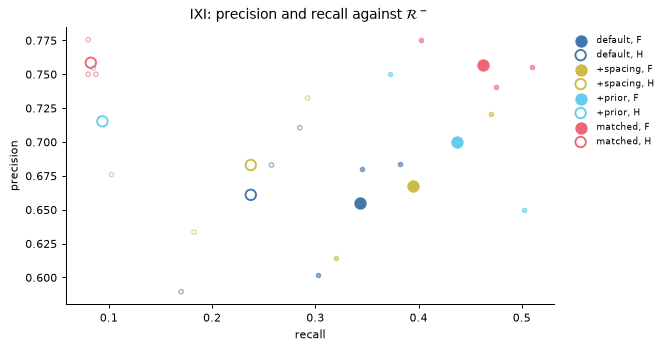

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
plot_precision_recall(ax, results)
ax.set_title(r"IXI: precision and recall against $\mathcal{R}^-$")
plt.show()

From default to matched, the IXI means of set F move from precision 0.6550 and recall 0.3433 to
0.7568 and 0.4625. In set H precision rises from 0.6610 to 0.7585, and recall falls from 0.2375
to 0.0825. Set H has only 40 distinct prior states, all at one slice level, so its recall
measures how much of $\mathcal{R}^-$ forty seeds can reach.

**Distance to the seed (Figure 2b, bottom; post hoc).** With $d$ the Euclidean distance between
two images after removing the mean intensity of each, $\mathcal{X}$ the training slices and
$\mathcal{X}_{-j}$ those of subjects other than that of seed $\mathbf{x}^{(j)}$, a sample
$\tilde{\mathbf{x}}$ of that seed has

$$q_{\text{seed}}=\frac{d(\tilde{\mathbf{x}},\mathbf{x}^{(j)})}{D_{\text{ref}}},\qquad
q_{\text{train}}=\frac{\min_{\mathbf{x}\in\mathcal{X}_{-j}}d(\tilde{\mathbf{x}},\mathbf{x})}
{D_{\text{ref}}},$$

where $D_{\text{ref}}$ is the median distance from an $\mathcal{R}^-$ image to its nearest
training image (report, Section 4.3; for set H, $q_{\text{train}}$ takes the minimum over all of
$\mathcal{X}$). On this scale 1 is as far as a new real image is from the training set. The
plot shows the median over the samples of each run (small markers), their seed means (large
markers), the interquartile range of the samples pooled over the runs (vertical lines) and the
interquartile range of the $\mathcal{R}^-$ images (grey band). This measure was not
pre-registered: the panel is post hoc.

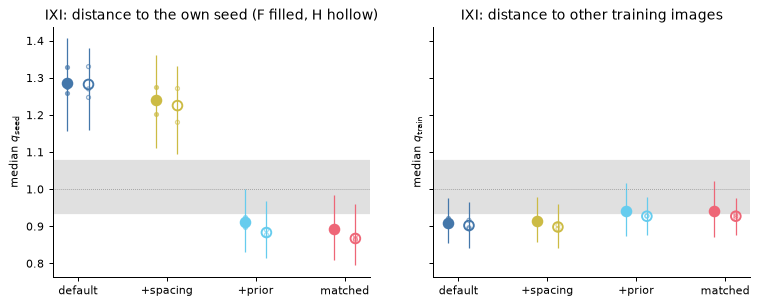

In [17]:
fig, (ax_s, ax_t) = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
plot_distance(ax_s, results, "seed")
plot_distance(ax_t, results, "train")
ax_s.set_title(r"IXI: distance to the own seed (F filled, H hollow)")
ax_t.set_title(r"IXI: distance to other training images")
plt.show()

From default to matched the median distance to the own seed falls from 1.287 to 0.893 (set F)
and from 1.282 to 0.867 (set H). Both matched values lie below the grey band (0.936–1.078), so
the median matched sample is closer to its seed than three in four new real images are to the
training set.
The distance to other training images rises from 0.910 to 0.940 (F) and from 0.902 to 0.927 (H).

**Spectral error per octave (Figure 2c).** The octave error compares the radial variance
profile $\bar P(o)$ of the 2,000 samples of set F with that of the reference $\mathcal{R}$, in
the eight octaves of Section 4:

$$e_o=\log_{10}\bar P_{gen}(o)-\log_{10}\bar P_{real}(o).$$

$e_o=0$ means that the samples vary as much as real images in octave $o$, and $e_o<0$ that they
vary too little; $e_o=-0.1$ is a variance $10^{0.1}\approx1.26$ times too small. Lines are seed
means and dots are runs.

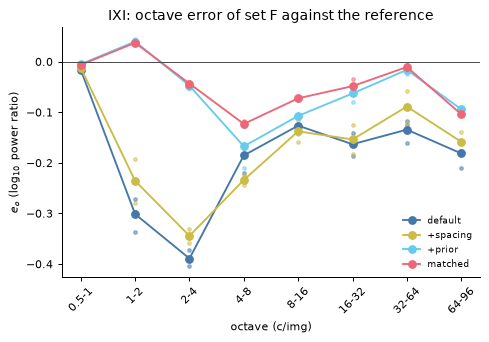

In [18]:
fig, ax = plt.subplots(figsize=(6, 3.6))
plot_octave_errors(ax, results)
ax.set_title("IXI: octave error of set F against the reference")
plt.show()

The default runs lack variance at 1–2 and 2–4 c/img ($e_o=-0.302$ and $-0.389$). With the
24 px prior (+prior and matched) the error in these two octaves stays within 0.05 of zero. At
24 px the prior keeps the frequencies below about 1.8 c/img, so there the error reflects the seed
rather than the chain (report, Section 4.3). The octave error sees how much the images vary at
each scale but not what varies, so we read it next to precision.

Figure 2 of the report puts these panels together with sample images (panel a) and the
band-pass images of one slice (the strip of panel c). Its caption draft, every number it shows
and the command that draws it are in `docs/RESULTS/paper/F2.md`.

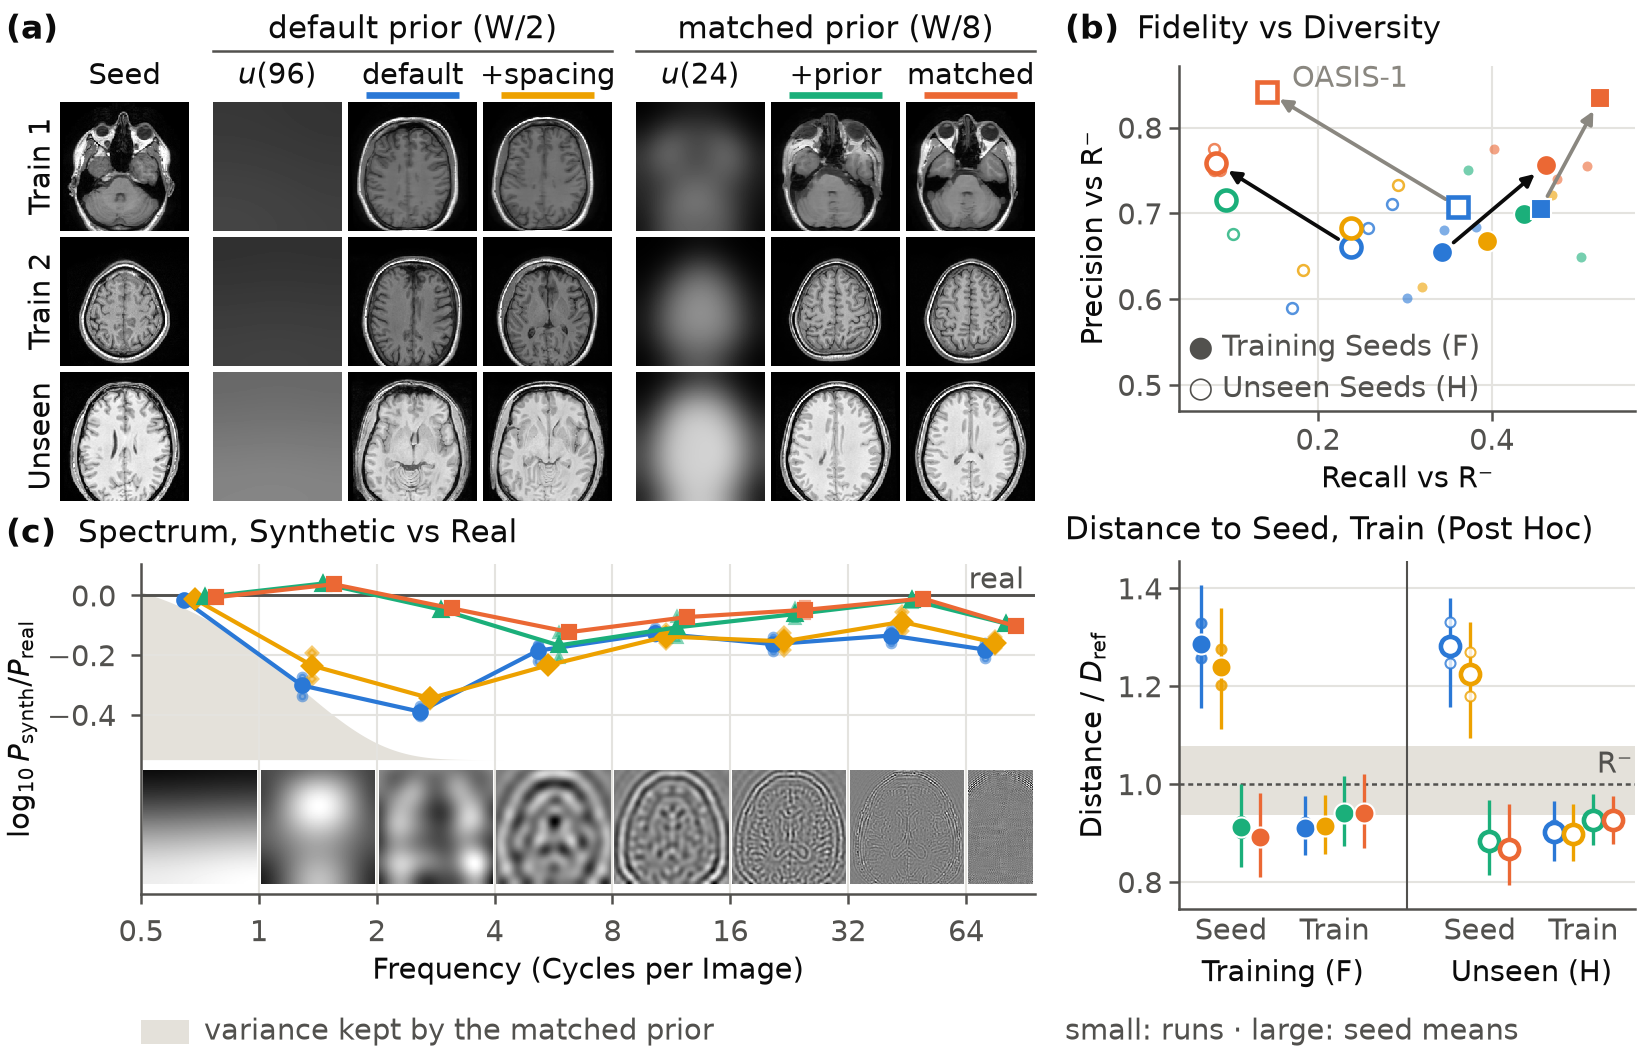

In [19]:
ShowImage(filename=str(REPO / "docs" / "RESULTS" / "paper" / "f2_arms.png"), width=900)

## 8. Where the code lives

| Step | Function | File |
|---|---|---|
| $F(t)$ (Section 3) | `DCTBlur`; `heat` above | `model_code/utils.py` |
| $\lambda_i$, $c_i$ | `eigenvalues`, `radial_index` | `ihdm/spectral/power.py` |
| $P_i$ (Section 4) | `mode_power` | `ihdm/spectral/power.py` |
| stored $P_i$ | `python -m ihdm.cli.profile_data` | `ihdm/cli/profile_data.py` |
| spectrum, exponent | `radial_spectrum`, `fit_alpha` | `ihdm/spectral/power.py` |
| octave shares | `octave_bins`, `octave_shares` | `ihdm/spectral/power.py` |
| synthetic $c^{-2}$ | `power_law` | `ihdm/spectral/power.py` |
| $I$ (Section 5) | `inherited_share` | `ihdm/spectral/power.py` |
| prior, reverse chain | `prior_state`, `reverse_chain` | `ihdm/sampling/chain.py` |
| log spacing (Section 6) | `log_schedule` | `ihdm/spectral/schedules.py` |
| matched spacing | `matched_schedule` (Algorithm 1) | `ihdm/spectral/schedules.py` |
| frozen schedules | `python -m ihdm.cli.build_schedules` | `ihdm/cli/build_schedules.py` |
| $E_k$, spread | `per_level_removed`, `per_level_spread` | `ihdm/spectral/schedules.py` |
| levels per octave | `levels_per_octave` | `ihdm/spectral/schedules.py` |
| precision, recall (Section 7) | `set_metrics` | `ihdm/analysis/heldout_fidelity.py` |
| $q_{\text{seed}}$, $q_{\text{train}}$ | `nearest_training` | `ihdm/analysis/seed_distance.py` |
| $e_o$ | `lsd` | `ihdm/metrics/spectral.py` |
| Figure 2 | `python -m ihdm.cli.paper_f2` | `ihdm/analysis/paper_f2.py` |
| `assets/` | `python -m ihdm.cli.build_tutorial_assets` | `ihdm/cli/build_tutorial_assets.py` |
| Section 7 plots | `plot_distance` and two more | `ihdm/analysis/tutorial.py` |

To rebuild the files this notebook reads: the first two commands need the data drive, and
`paper_f2` also needs the evaluation archives (its full arguments are at the end of
`docs/RESULTS/paper/F2.md`; the other reproduction commands are in Section 13 of
`docs/RESULTS/results_discussion.md`).

```bash
python -m ihdm.cli.build_tutorial_assets --force   # assets/
python -m ihdm.cli.profile_data                    # docs/RESULTS/data_profile*
python -m ihdm.cli.paper_f2 ...                    # docs/RESULTS/paper/f2_arms.*, F2.md
```

To regenerate and run this notebook from its source:

```bash
jupytext --to ipynb ihdm_mri_tutorial.py
jupyter nbconvert --to notebook --execute --inplace ihdm_mri_tutorial.ipynb
jupyter nbconvert --to html --output-dir docs/tutorial ihdm_mri_tutorial.ipynb
```

In [20]:
print(f"notebook run time: {time.perf_counter() - started:.1f} s")

notebook run time: 2.0 s
